# EMG classification: train on calibration data, test on a live game session

The model is trained on the five calibration files, then used to classify the live
recording at the times of the company's decisions. Our decisions are compared with
theirs to measure agreement.

Run the cells from top to bottom. After editing any file in `emg_pipeline/`, restart
the kernel so the changes are picked up.

In [11]:
%matplotlib inline

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from emg_pipeline import (
    CLASS_LABELS,
    PipelineConfig,
    build_classifier,
    build_training_set,
    classify_live,
    compute_metrics,
    filter_signal,
    load_session,
    plot_calibration_signals,
    plot_confusion_matrix,
    plot_decision_timelines,
    plot_decision_windows,
)

# Settings live in one place. To test overlapping windows, try window_ms=128.
cfg = PipelineConfig(window_ms=64, decision_lag=5)  # decision_lag=0 turns the shift off
print(cfg)

PipelineConfig(fs=1000, window_ms=64, train_hop_ms=32, highpass_hz=20.0, lowpass_hz=400.0, filter_order=2, causal_filter=True, calibration_trim_ms=0, decision_lag=5)


## 1. Load the session

Reads the 7 CSV files from the `data` folder.

In [12]:
session = load_session()
print(f"Data folder: {session.source}")
for label, signal in session.calibration.items():
    print(f"  calibration {label:<7}: {signal.shape[0]} samples ({signal.shape[0] / cfg.fs:.1f} s)")
print(f"  live recording     : {session.live.shape[0]} samples ({session.live.shape[0] / cfg.fs:.1f} s)")
print(f"  company decisions  : {len(session.decisions)}")

display(
    pd.Series(session.decisions)
    .value_counts()
    .reindex(CLASS_LABELS)
    .rename("Company decisions")
    .to_frame()
)

Data folder: C:\Users\nicol\EMG-Signal-Classification\data
  calibration Rest   : 4000 samples (4.0 s)
  calibration Left   : 4000 samples (4.0 s)
  calibration Right  : 4000 samples (4.0 s)
  calibration Rotate : 4000 samples (4.0 s)
  calibration Drop   : 4000 samples (4.0 s)
  live recording     : 1826928 samples (1826.9 s)
  company decisions  : 28544


,Company decisions
Rest,15300
Left,3415
Right,2890
Rotate,3273
Drop,3666


## 2. Calibration signals

One column per movement and one row per channel. These files are already filtered.

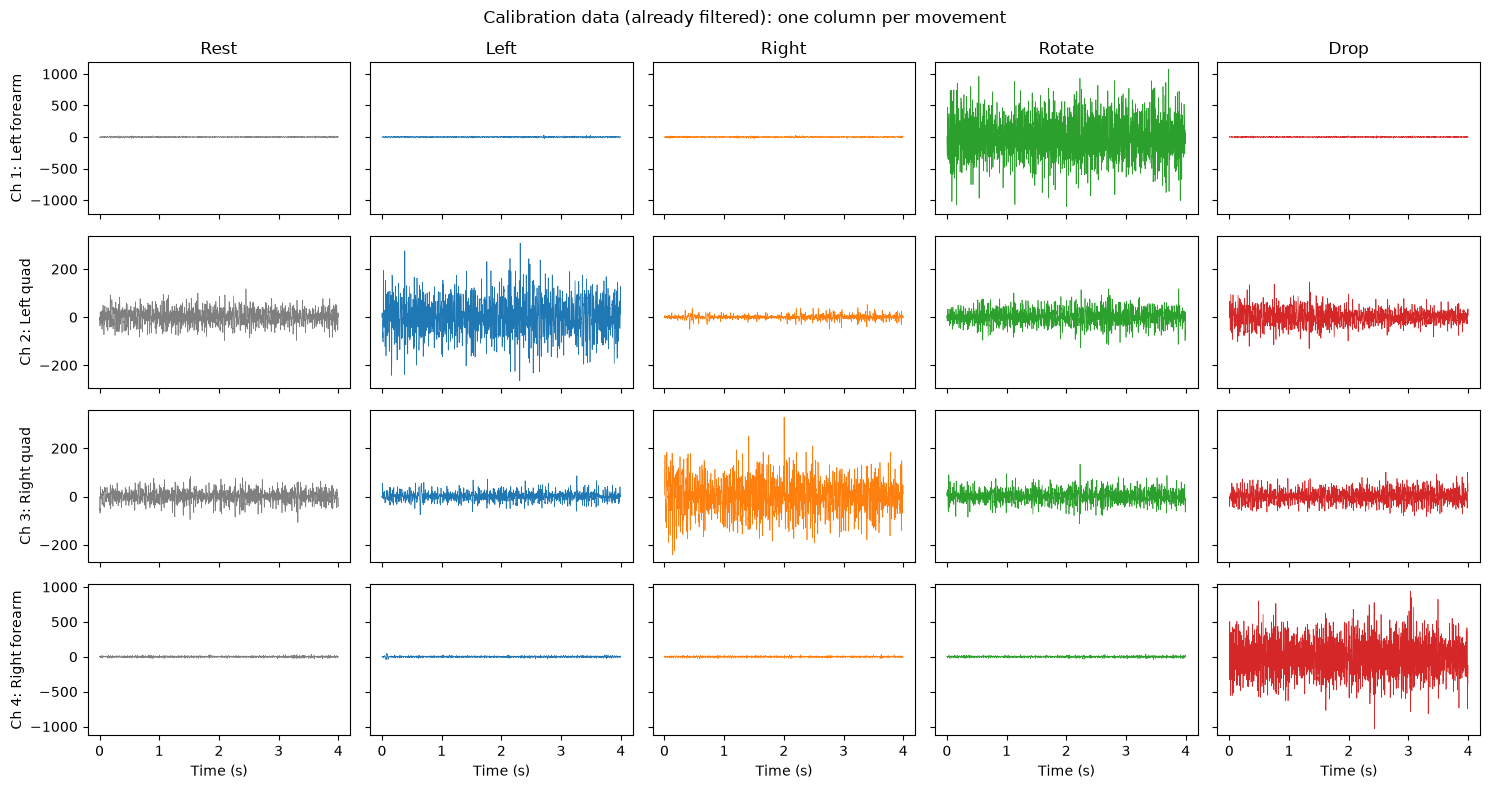

In [13]:
fig = plot_calibration_signals(session, cfg)
plt.show()

## 3. Train the model

Cuts the calibration files into windows, extracts 16 features per window, and fits LDA followed by Gaussian Naive Bayes.

In [14]:
training = build_training_set(session, cfg)
print(f"Training windows: {training.X.shape[0]} ({training.X.shape[1]} features each)")
display(
    pd.Series(training.y)
    .value_counts()
    .reindex(CLASS_LABELS)
    .rename("Training windows")
    .to_frame()
)

model = build_classifier().fit(training.X, training.y)

Training windows: 620 (16 features each)


,Training windows
Rest,124
Left,124
Right,124
Rotate,124
Drop,124


The calibration windows in all four LDA dimensions (1 vs 2 on the left, 3 vs 4 on the right):

Share of the class separation captured by each dimension: [0.515 0.292 0.178 0.015]


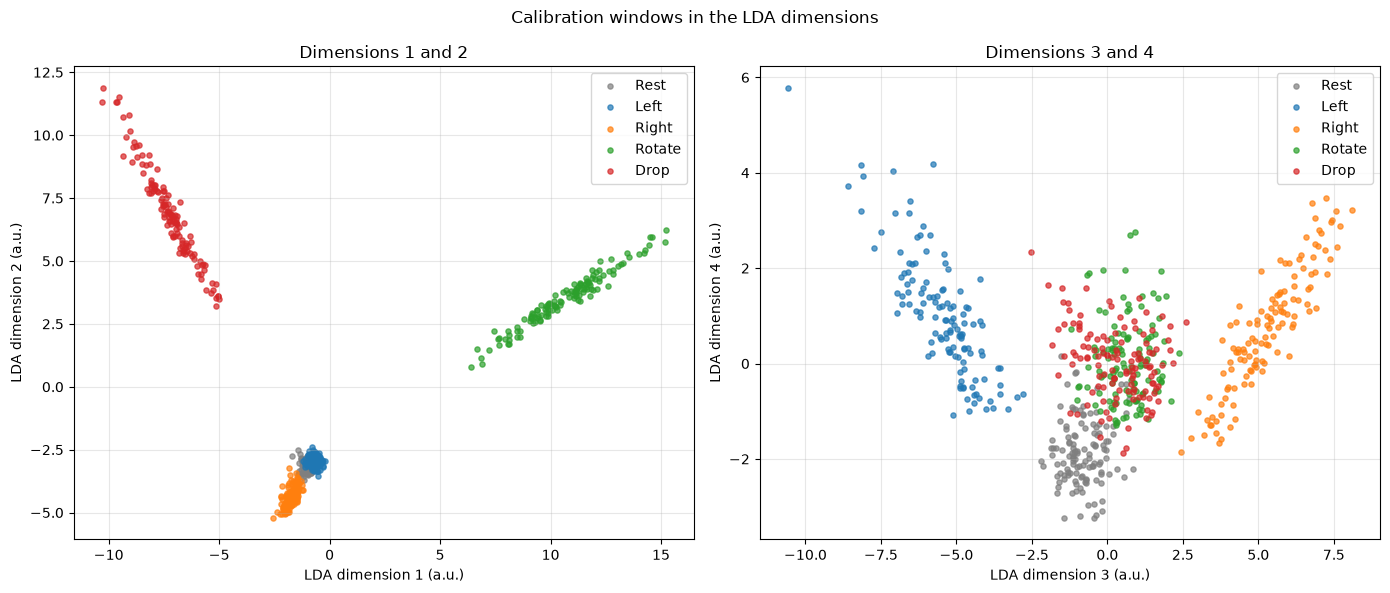

In [15]:
from emg_pipeline.plots import CLASS_COLORS

lda = model.named_steps["lda"]
projected = lda.transform(training.X)
print("Share of the class separation captured by each dimension:", lda.explained_variance_ratio_.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for axis, (a, b) in zip(axes, [(0, 1), (2, 3)]):
    for label in CLASS_LABELS:
        mask = training.y == label
        axis.scatter(
            projected[mask, a],
            projected[mask, b],
            s=14,
            alpha=0.7,
            color=CLASS_COLORS[label],
            label=label,
        )
    axis.set_xlabel(f"LDA dimension {a + 1} (a.u.)")
    axis.set_ylabel(f"LDA dimension {b + 1} (a.u.)")
    axis.set_title(f"Dimensions {a + 1} and {b + 1}")
    axis.grid(alpha=0.3)
    axis.legend()
fig.suptitle("Calibration windows in the LDA dimensions")
fig.tight_layout()
plt.show()

## 4. Classify the live session

The raw live data is filtered, then one window ending at each of the company's
decision times is classified.

In [16]:
live = classify_live(session, model, cfg)
print(
    f"Compared {len(live.predicted)} decisions "
    f"({live.skipped} skipped for lack of a full window, "
    f"{cfg.decision_lag} dropped at the end for the {cfg.decision_lag}-step shift)."
)

Compared 28539 decisions (0 skipped for lack of a full window, 5 dropped at the end for the 5-step shift).


## 5. Accuracy

The company's decisions are the reference. **Recall** is how many of the company's
decisions for a movement we also made. **Precision** is how many of our decisions
for a movement the company agrees with.

In [17]:
metrics = compute_metrics(live.actual, live.predicted)
print(f"Overall accuracy:  {metrics.accuracy:.1%}")
print(f"Balanced accuracy: {metrics.balanced_accuracy:.1%}  (average of the per-movement recalls)")
display(metrics.table().round(3))

Overall accuracy:  88.4%
Balanced accuracy: 86.9%  (average of the per-movement recalls)


,Precision,Recall,F1,Decisions
Movement,,,,
Rest,0.895,0.902,0.898,15300
Left,0.858,0.792,0.823,3415
Right,0.696,0.827,0.756,2890
Rotate,0.954,0.863,0.906,3270
Drop,0.982,0.959,0.971,3664


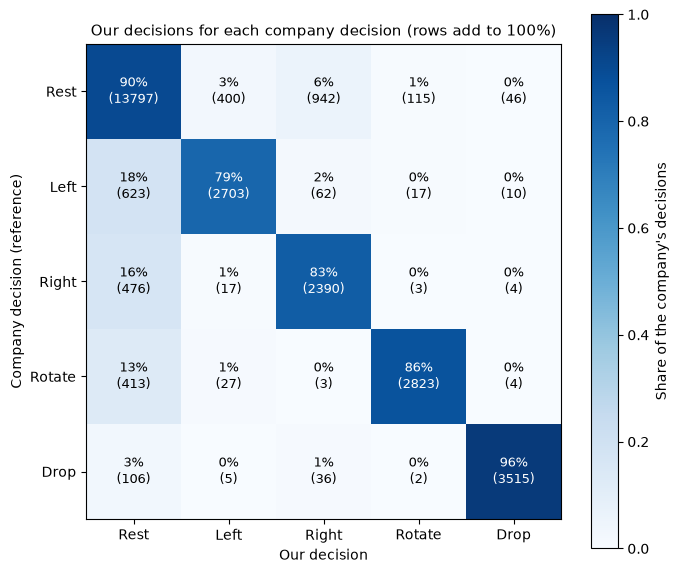

In [18]:
fig = plot_confusion_matrix(metrics)
plt.show()

## 6. Decision timelines

Each movement is drawn at its own height. The time axis is the time of the signal our
decisions were based on, so the company's decisions are lined up with it using the
shift set in `decision_lag`.

**Whole session:** the company's decisions on top and ours below.

**Zoomed view:** from top to bottom, the company's decisions, our decisions, and the
filtered amplitude of channels 1 to 4. Each vertical line marks the end of one decision
window, and windows where we disagree with the company are shaded red.

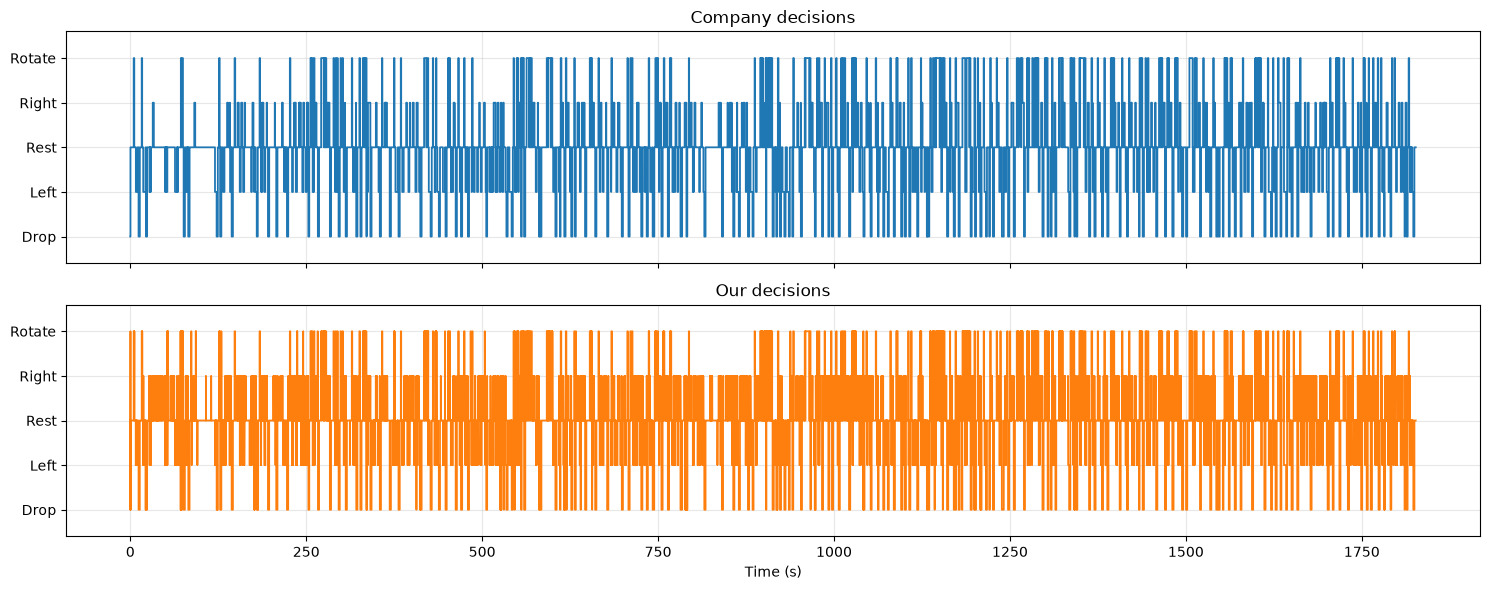

In [19]:
# Whole session
fig = plot_decision_timelines(live.window_end_s, live.actual, live.predicted)
plt.show()

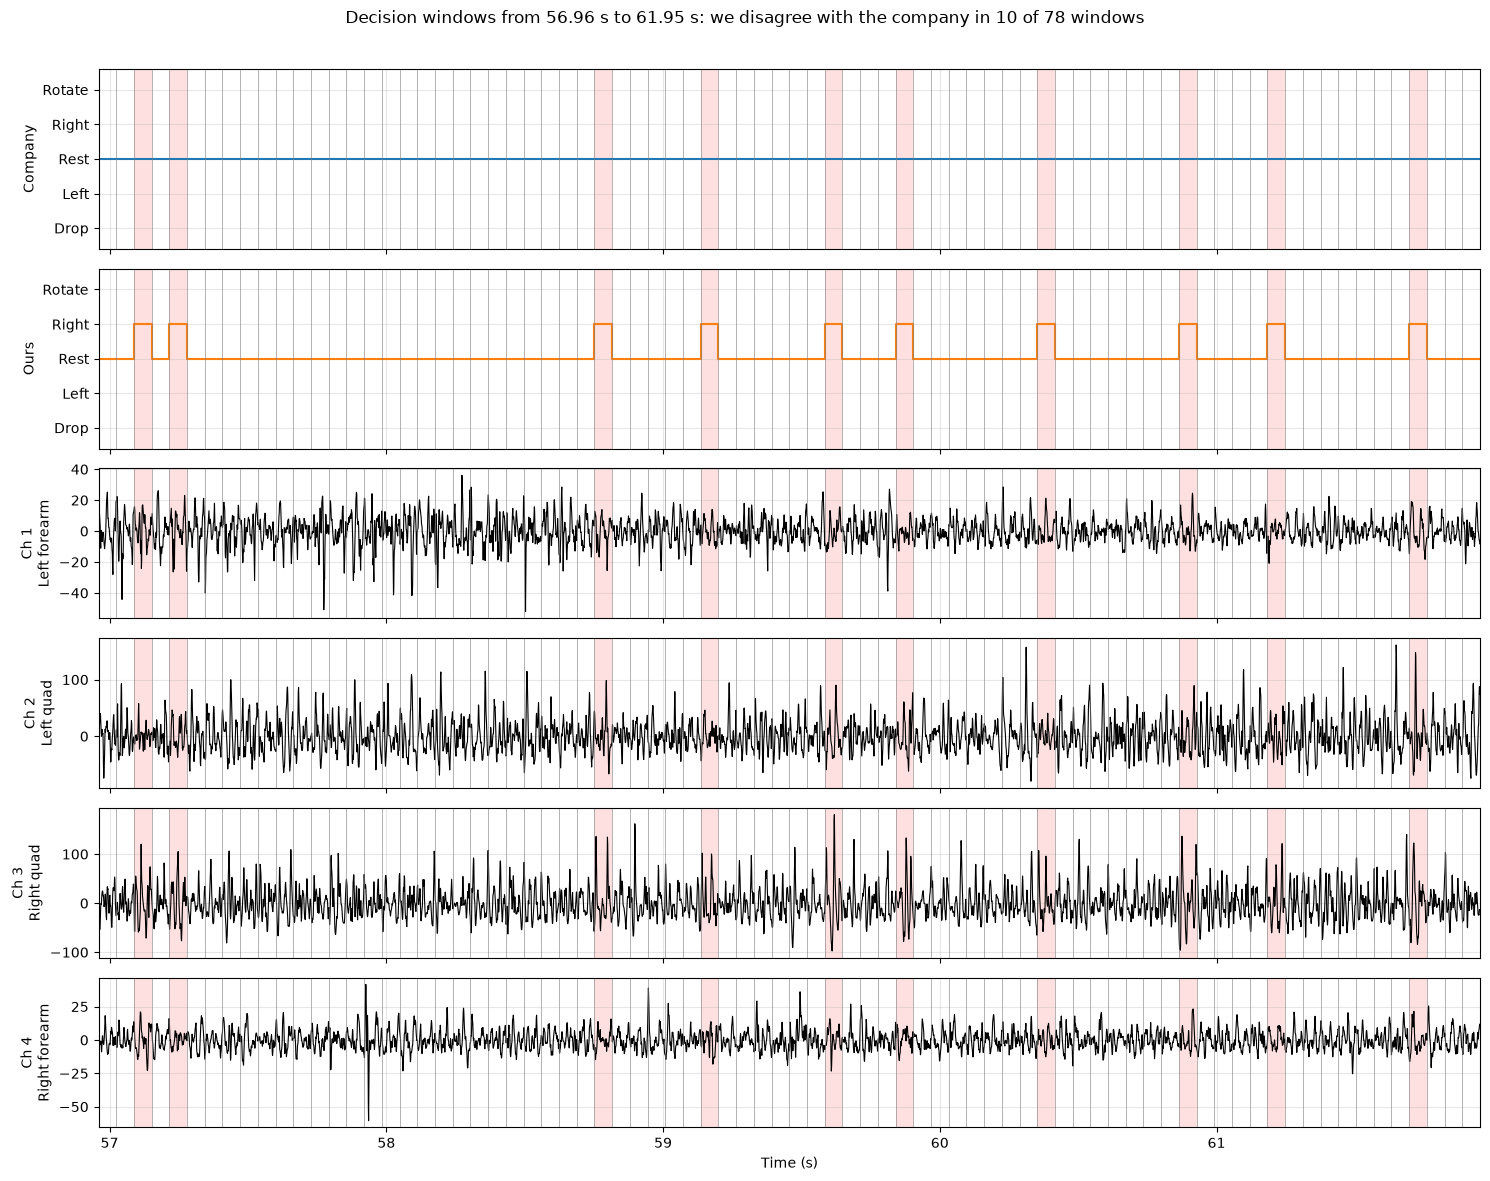

In [30]:
# Zoomed view. Change START_S and DURATION_S to look at other parts of the session.
# Keep DURATION_S short (a few seconds) so the individual windows are visible.
START_S = 57
DURATION_S = 5

filtered_live = filter_signal(session.live, cfg)
fig = plot_decision_windows(live, filtered_live, cfg, start_s=START_S, duration_s=DURATION_S)
plt.show()